In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_radial_spectrum, partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [3]:
# def iterative_filtering3D(fieldX, fieldY, fieldZ, index, Xi=1.6):
#     fif = fifpy.MIF(NIMFs=4,alpha=30, Xi=Xi)
#     fif.run(fieldX)
#     mif_x = fif.IMC
#     logm = np.array([fif.data['stats_list']['logMx'],fif.data['stats_list']['logMy']]).min(axis=0)
#     fif.run(fieldY, M=logm)
#     mif_y = fif.IMC
#     fif.run(fieldZ, M=logm)
#     mif_z = fif.IMC
#     filtered_x = np.sum(mif_x[index:], axis=0)
#     filtered_y = np.sum(mif_y[index:], axis=0)
#     filtered_z = np.sum(mif_z[index:], axis=0)
#     return filtered_x, filtered_y, filtered_z

def iterative_filtering3D(fieldX, fieldY, fieldZ, index, Xi=1.6):
    fif = fifpy.MIF(NIMFs=2,alpha=30, Xi=Xi)
    fif.run(fieldX,M=1000)
    mif_x = fif.IMC
    logm = np.array([fif.data['stats_list']['logMx'],fif.data['stats_list']['logMy']]).min(axis=0)
    fif.run(fieldY, M=logm)
    mif_y = fif.IMC
    fif.run(fieldZ, M=logm)
    mif_z = fif.IMC
    filtered_x = np.sum(mif_x[index:], axis=0)
    filtered_y = np.sum(mif_y[index:], axis=0)
    filtered_z = np.sum(mif_z[index:], axis=0)
    return filtered_x, filtered_y, filtered_z

[OK] beta=4
[OK] beta=1
[OK] beta=0.25
[OK] beta=16
[OK] beta=0.0625


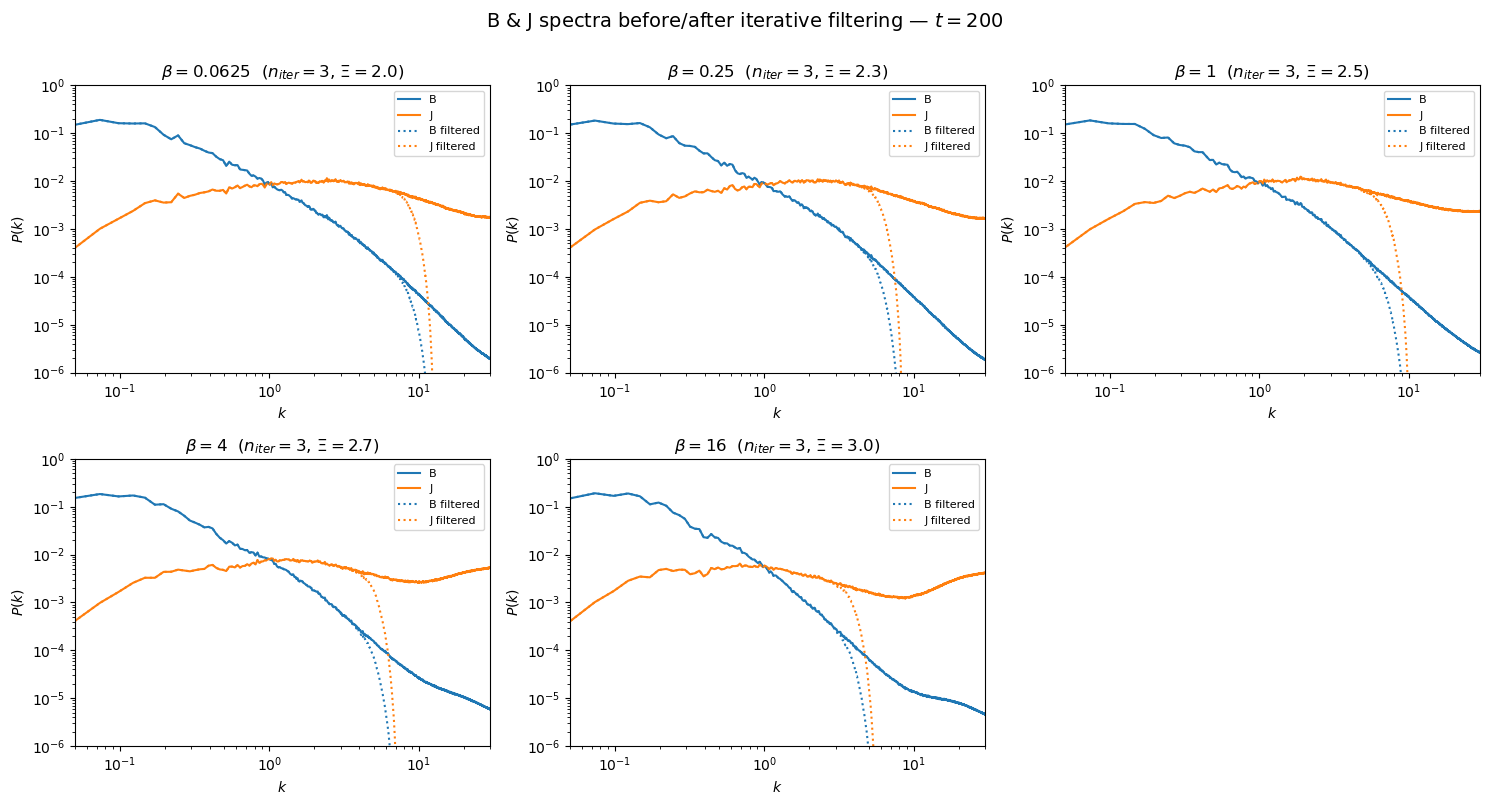


Saved -> JB_spectrum_all_betas.png


In [4]:
# =====================================================================
# B & J power spectra, before vs after iterative filtering, for ALL betas.
# One panel per beta in a comparison grid. Heavy work (filter + spectra) runs
# in parallel over beta; the parent draws the grid.
#
# Must already exist in your session:
#   partial_x_fft, partial_y_fft, compute_radial_spectrum, iterative_filtering3D
# =====================================================================

import os
import math
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
import numpy as np
import matplotlib.pyplot as plt
import h5py

# -----------------------------
# USER SETTINGS
# -----------------------------
BETAS    = [0.0625, 0.25, 1, 4, 16]
TIME     = 200
SIM_TAG  = "ApJ"
BASE_FMT = str(DATA_ROOT) + "/beta_p_{beta}/beta_e_1"
dx = dy  = 0.0625
cache_dir = str(CACHE / "filtered_cache_Jz")        # reuse filtered fields if already computed
N_WORKERS = min(len(BETAS), os.cpu_count() or 1)
XLIM = (5e-2, 30)
YLIM = (1e-6, 1)
OUT_FIG = str(RESULTS / "JB_spectrum_all_betas.png")

FILTER_PARAMS_BETA = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def filter_params(beta):
    try:
        return FILTER_PARAMS_BETA[beta]
    except KeyError:
        raise KeyError(f"no filter params for beta={beta}; add it to FILTER_PARAMS_BETA")


def _sum_spectrum(fx, fy, fz):
    """Radial spectrum of |F|^2 summed over the three components. Returns (kk, sp)."""
    sx = compute_radial_spectrum(fx, dx, dy)
    sy = compute_radial_spectrum(fy, dx, dy)
    sz = compute_radial_spectrum(fz, dx, dy)
    return sx.kk, (sx.sp + sy.sp + sz.sp)


def compute_spectra(beta, time):
    n_iter, Xi = filter_params(beta)
    base = BASE_FMT.format(beta=beta)
    with h5py.File(f"{base}/Bx_{SIM_TAG}_t{time}.h5", "r") as fBx, \
         h5py.File(f"{base}/By_{SIM_TAG}_t{time}.h5", "r") as fBy, \
         h5py.File(f"{base}/Bz_{SIM_TAG}_t{time}.h5", "r") as fBz:
        Bx = fBx["DS1"][:].T
        By = fBy["DS1"][:].T
        Bz = fBz["DS1"][:].T

    # filtered fields (cached; same naming as the rest of the pipeline)
    cache = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache):
        d = np.load(cache)
        Bxf, Byf, Bzf = d["Bx"], d["By"], d["Bz"]
    else:
        Bxf, Byf, Bzf = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache, Bx=Bxf, By=Byf, Bz=Bzf)

    # J = curl B  (Jx = dBz/dy, Jy = -dBz/dx, Jz = dBy/dx - dBx/dy); dx == dy here
    Jx  = partial_y_fft(Bz,  dy);  Jy  = -partial_x_fft(Bz,  dx)
    Jz  = partial_x_fft(By,  dx) - partial_y_fft(Bx,  dy)
    Jxf = partial_y_fft(Bzf, dy);  Jyf = -partial_x_fft(Bzf, dx)
    Jzf = partial_x_fft(Byf, dx) - partial_y_fft(Bxf, dy)

    kk, spB  = _sum_spectrum(Bx,  By,  Bz)
    _,  spJ  = _sum_spectrum(Jx,  Jy,  Jz)
    _,  spBf = _sum_spectrum(Bxf, Byf, Bzf)
    _,  spJf = _sum_spectrum(Jxf, Jyf, Jzf)

    return {"beta": beta, "n_iter": n_iter, "Xi": Xi, "kk": np.asarray(kk),
            "spB": np.asarray(spB), "spJ": np.asarray(spJ),
            "spBf": np.asarray(spBf), "spJf": np.asarray(spJf)}


# -----------------------------
# Dispatch (parallel over beta) -> draw grid
# -----------------------------
results = {}
if N_WORKERS == 1:
    for b in BETAS:
        try:
            results[b] = compute_spectra(b, TIME)
            print(f"[OK] beta={b}", flush=True)
        except FileNotFoundError:
            print(f"[SKIP] beta={b}: missing file", flush=True)
        except Exception as e:
            print(f"[FAIL] beta={b}: {type(e).__name__}: {e}", flush=True)
else:
    ctx = mp.get_context("fork")
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
        futs = {ex.submit(compute_spectra, b, TIME): b for b in BETAS}
        for fut in as_completed(futs):
            b = futs[fut]
            try:
                results[b] = fut.result()
                print(f"[OK] beta={b}", flush=True)
            except FileNotFoundError:
                print(f"[SKIP] beta={b}: missing file", flush=True)
            except Exception as e:
                print(f"[FAIL] beta={b}: {type(e).__name__}: {e}", flush=True)

# -----------------------------
# Comparison grid
# -----------------------------
ncols = 3
nrows = math.ceil(len(BETAS) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)

for idx, beta in enumerate(BETAS):
    ax = axes[idx // ncols][idx % ncols]
    if beta not in results:
        ax.set_title(f"beta={beta} (no data)")
        ax.axis("off")
        continue
    r = results[beta]
    lB, = ax.loglog(r["kk"], r["spB"], label="B")
    lJ, = ax.loglog(r["kk"], r["spJ"], label="J")
    ax.loglog(r["kk"], r["spBf"], ":", color=lB.get_color(), label="B filtered")
    ax.loglog(r["kk"], r["spJf"], ":", color=lJ.get_color(), label="J filtered")
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_xlabel(r"$k$"); ax.set_ylabel(r"$P(k)$")
    ax.set_title(rf"$\beta={beta}$  ($n_{{iter}}={r['n_iter']}$, $\Xi={r['Xi']}$)")
    ax.legend(fontsize=8)

for idx in range(len(BETAS), nrows * ncols):
    axes[idx // ncols][idx % ncols].axis("off")

fig.suptitle(rf"B & J spectra before/after iterative filtering — $t={TIME}$", y=1.0, fontsize=14)
fig.tight_layout()
fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
plt.show()
print(f"\nSaved -> {OUT_FIG}", flush=True)